In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
folsom_img_path = './20141114_201400.jpg'
modena_img_path = './2024_06_10__10_00_00_rpi_hq_imx477r_fisheye_rgb_camera.jpg'
karpicko_img_path = './2024_08_13__10_00_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg'
poznan_img_path = './2024_10_20__10_00_00_rpi_hq_imx477r_fisheye_rgb_camera_600.jpg'

In [3]:
img_folsom = np.asarray(Image.open(folsom_img_path))
img_modena = np.asarray(Image.open(modena_img_path))
img_karpicko = np.asarray(Image.open(karpicko_img_path))
img_poznan = np.asarray(Image.open(poznan_img_path))

In [4]:
img_poznan[:, 254:-254].shape, img_folsom.shape, (2028-1520) / 2

((1520, 1520, 3), (1536, 1536, 3), 254.0)

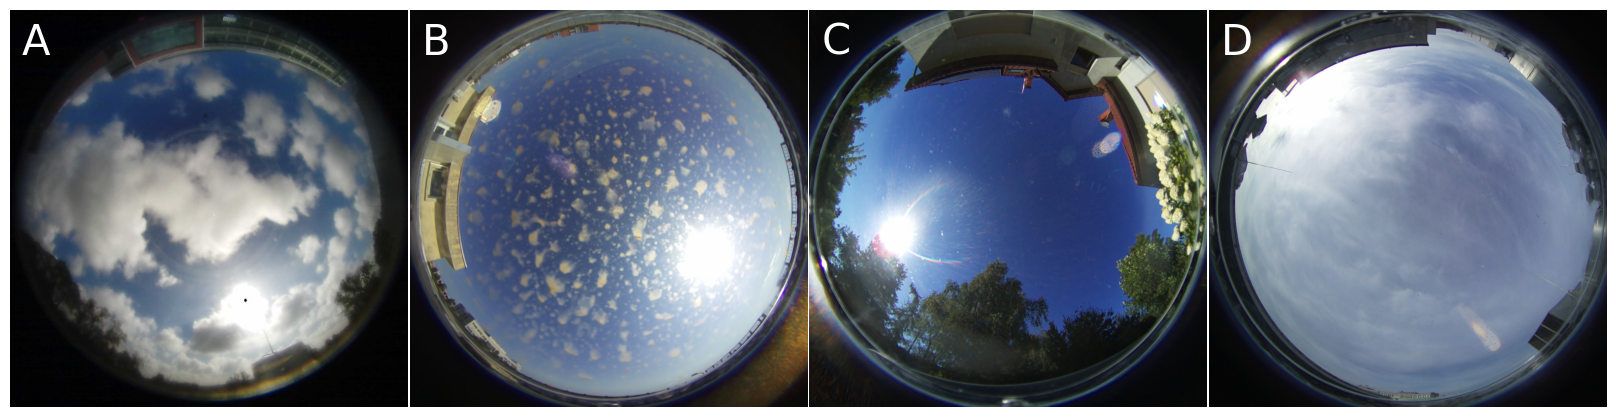

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(img_folsom)
ax[1].imshow(img_modena[:, 254:-254])
ax[2].imshow(img_karpicko[:, 254:-254])
ax[3].imshow(img_poznan[:, 254:-254])

for _ax in ax.flatten():
    _ax.axis('off')
    # set A, B, C, D labels
    _ax.text(0.03, 0.97, chr(ord('A') + ax.flatten().tolist().index(_ax)), transform=_ax.transAxes, color='white', fontsize=30, va='top')

plt.tight_layout(pad=0.1)
# plt.savefig('sky_images.pdf', transparent=True)

In [6]:
periods_path = Path('../../data/Modena/modena_periods_4_5_15.pkl')

with open(periods_path, 'rb') as f:
    periods = pickle.load(f)

target_irradiances = np.stack([p['target_irradiance'] for p in periods])
offline_outputs = np.load(f'{str(periods_path.parent / periods_path.stem)}_raw_output.npy')
tta_outputs = np.load(f'{str(periods_path.parent / periods_path.stem)}_tta_output.npy')
tta_updates = np.load(f'{str(periods_path.parent / periods_path.stem)}_tta_updates.npy')

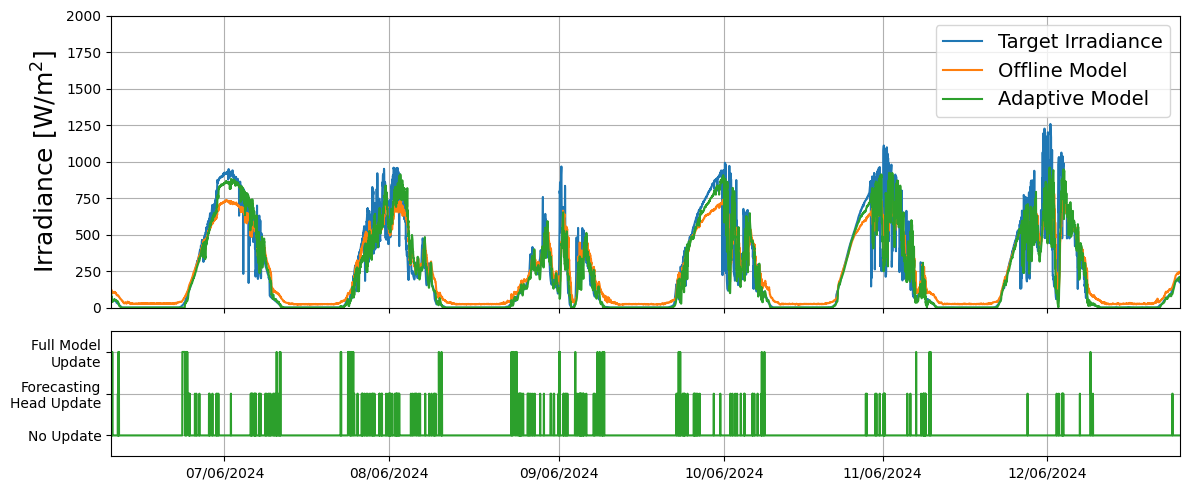

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), gridspec_kw={'height_ratios': [3.5, 1.5]}, sharex=True)

# Example usage
ax[0].plot(target_irradiances[:len(tta_outputs)], c='tab:blue')
ax[0].plot(offline_outputs, c='tab:orange')
ax[0].plot(tta_outputs, c='tab:green')
ax[0].legend(['Target Irradiance', 'Offline Model', 'Adaptive Model'], loc='upper right', fontsize=14)
# ax[0].legend(['Target Irradiance', 'Adaptive Model'])
ax[0].grid(True)
ax[0].set_ylabel('Irradiance [W/m$^2$]', fontsize=18)
ax[0].set_xlim(0, len(target_irradiances[:len(tta_outputs)]))
if periods_path.parent.name == 'Karpicko':
    ax[0].set_ylim(0, 1200)
    ax[0].set_xticks([770, 2210, 3650, 4930, 6300, 7500, 8700], ['12/08/2024', '13/08/2024', '14/08/2024', '15/08/2024', '16/08/2024', '17/08/2024', '18/08/2024'])
elif periods_path.parent.name == 'Poznan':
    ax[0].set_ylim(0, 800)
    ax[0].set_xticks([720, 2150, 3550, 5000, 6450, 7750, 9200, 10650], ['19/10/2024', '20/10/2024', '21/10/2024', '22/10/2024', '23/10/2024', '24/10/2024', '25/10/2024', '26/10/2024'])
elif periods_path.parent.name == 'Modena':
    ax[0].set_ylim(0, 2000)
    ax[0].set_xticks([1000, 2450, 3950, 5400, 6800, 8250], ['07/06/2024', '08/06/2024', '09/06/2024', '10/06/2024', '11/06/2024', '12/06/2024'])
else:
    raise ValueError('Unknown dataset')

ax[1].plot(tta_updates, c='tab:green')
ax[1].grid(True)
ax[1].set_ylim(-0.5, 2.5)
ax[1].set_yticks([0, 1, 2], ['No Update', 'Forecasting\nHead Update', 'Full Model\nUpdate'], fontsize=10)
ax[1].set_xlim(0, len(tta_updates))

plt.tight_layout()
# plt.show()
# plt.savefig(f'irradiance_plot_{periods_path.parent.name.lower()}.pdf', transparent=True)